# CSC 240 Final Project: Feature Engineering

**Goal:** turn each abstract into numbers that measure how *specific* it is, so we can compare pre- and post-ChatGPT papers (H1).

Input: `abstracts_clean.csv.gz` (from `01_Data_Preprocessing`). Output: `features_abstracts.csv.gz`, one row per paper.

We measure three things:
1. numbers and units per 100 words
2. hedging words per 100 words
3. promotional words per 100 words

In [1]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

## Word lists

In [2]:
# hedging: words that soften a claim
HEDGES = [
    r"may", r"might", r"could", r"possibly", r"perhaps", r"probably", r"presumably", r"apparently", r"arguably",
    r"likely", r"unlikely", r"potentially", r"roughly", r"approximately", r"somewhat", r"relatively", r"fairly",
    r"rather", r"quite", r"largely", r"mostly", r"partly", r"partially", r"generally", r"typically", r"usually",
    r"often", r"sometimes", r"tends?", r"tended", r"tending",
    r"suggest(?:s|ed|ing)?", r"appear(?:s|ed|ing)?", r"seem(?:s|ed|ing)?",
    r"to (?:some|a certain) extent", r"in general", r"it is possible",
]

# promotional: words that praise the work
PROMO = [
    r"novel", r"innovative", r"innovation", r"groundbreaking", r"ground-breaking", r"cutting-edge", r"state-of-the-art",
    r"breakthrough", r"remarkabl[ey]", r"outstanding", r"superior", r"excellent", r"powerful", r"robust",
    r"comprehensive", r"unprecedented", r"pivotal", r"crucial", r"essential", r"transformative", r"revolutionary",
    r"revolutioniz\w+", r"significantly outperform\w*", r"substantially outperform\w*",
]

# words said to be more common in LLM-written text (extra check, not part of the specificity score)
LLM_MARKERS = [
    r"delv(?:e|es|ed|ing)", r"intricate", r"intricacies", r"meticulous(?:ly)?", r"commendable",
    r"showcas(?:e|es|ed|ing)", r"underscor(?:e|es|ed|ing)", r"realm", r"tapestry",
    r"leverag(?:e|es|ed|ing)", r"shed(?:s|ding)? light", r"paves? the way",
]

# units that can follow a number, with or without a space ("10 ms", "95 %")
UNITS = [
    r"%", r"percent", r"percentage points?", r"fold", r"times",
    r"ms", r"msec", r"ns", r"sec", r"seconds?", r"min", r"minutes?", r"hours?", r"hrs?", r"days?", r"weeks?", r"months?", r"years?", r"yrs?",
    r"gyr", r"myr", r"kyr", r"hz", r"khz", r"mhz", r"ghz", r"thz",
    r"ev", r"kev", r"mev", r"gev", r"tev", r"pev", r"kj", r"kw", r"mw", r"mv", r"ma", r"mk", r"nk", r"kg", r"mg", r"ug", r"kda",
    r"cm", r"mm", r"um", r"nm", r"km", r"kpc", r"mpc", r"gpc", r"pc", r"ly",
    r"mol", r"mmol", r"ml", r"kpa", r"mpa", r"gpa", r"atm", r"db", r"dbm", r"bits?", r"bytes?", r"kb", r"mb", r"gb", r"tb",
    r"flops", r"gflops", r"tflops", r"fps", r"msun", r"lsun",
]
# things we count ("1,200 samples"); only after real digits, because "[MATH] samples" is often just a variable
COUNTED = [
    r"samples?", r"patients?", r"participants?", r"subjects?", r"images?", r"parameters?", r"tokens?", r"datasets?",
    r"nodes?", r"qubits?", r"gpus?", r"layers?", r"classes", r"episodes?", r"galaxies", r"stars", r"papers?", r"users?",
]
# one-letter units, only when glued to the digit ("5K", "3x")
ATTACHED = [r"K", r"x", r"m", r"s", r"g", r"V", r"W", r"J"]

## Regular expressions
What counts as a number:
- not names like `GPT-4`, `COVID-19`, `3D` (the digit is attached to a word)
- not four-digit years (1900-2030)
- inside LaTeX math (the `math` column), only decimals, multi-digit numbers and percentages, so indices and exponents like `x_1`, `n^2` are ignored

In [3]:
def words_re(items):
    return re.compile(r"\b(?:" + "|".join(items) + r")\b", re.I)

HEDGE_RE = words_re(HEDGES)
PROMO_RE = words_re(PROMO)
LLM_RE   = words_re(LLM_MARKERS)

NUM_RE   = re.compile(r"(?<![\w.\-/])\d+(?:[.,]\d+)*(?![A-Za-z\-/]|\d)")        # standalone numbers, also "95%"
YEAR_RE  = re.compile(r"(?<![\w.\-/])(?:19\d\d|20[0-3]\d)(?![\w.,\-/])")        # four-digit years
UNIT_RE  = re.compile(r"(?:(?<![\w.\-/])\d[\d.,]*\s?(?:" + "|".join(UNITS + COUNTED) + r")"      # "10 ms", "1,200 samples"
                      r"|\[MATH\]\s?(?:" + "|".join(UNITS) + r"))(?![A-Za-z])"                    # "[MATH] GeV"
                      r"|(?<![\w.\-/])\d[\d.,]*(?-i:" + "|".join(ATTACHED) + r")(?![A-Za-z])", re.I)   # "5K", "3x"
MATHNUM_RE = re.compile(r"\d+\.\d+|\d{2,}|\d+\s*\\?%")                          # quantities inside math
WORD_RE  = re.compile(r"[A-Za-z]+(?:['\-][A-Za-z]+)*")
PLACEHOLDER = re.compile(r"\[(?:MATH|URL)\]")
SENT_END = re.compile(r"(?<=[.!?])\s+(?=[A-Z\[])")

## Feature function
Takes a table with the cleaned text and returns one row of features per paper.

In [4]:
def featurize(df, text_col="abstract", math_col="math"):
    text = df[text_col]
    plain = text.str.replace(PLACEHOLDER, " ", regex=True)   # text without [MATH] and [URL]
    low = plain.str.lower()

    out = pd.DataFrame(index=df.index)
    out["n_words"] = plain.map(lambda s: len(WORD_RE.findall(s)))
    rate = lambda count: 100 * count / out["n_words"]         # count per 100 words

    # 1. numbers and units
    out["n_numbers"] = text.str.count(NUM_RE) - text.str.count(YEAR_RE)
    out["n_units"] = text.str.count(UNIT_RE)
    out["n_math_numbers"] = df[math_col].str.count(MATHNUM_RE)
    out["numbers_per100"] = rate(out.n_numbers + out.n_math_numbers)
    out["units_per100"] = rate(out.n_units)
    out["numunit_per100"] = rate(out.n_numbers + out.n_math_numbers + out.n_units)
    out["has_number"] = ((out.n_numbers + out.n_math_numbers) > 0).astype(int)

    # 2. hedging, 3. promotional words, and the LLM word check
    out["n_hedges"] = low.str.count(HEDGE_RE)
    out["n_promo"] = low.str.count(PROMO_RE)
    out["n_llm"] = low.str.count(LLM_RE)
    out["hedge_per100"] = rate(out.n_hedges)
    out["promo_per100"] = rate(out.n_promo)
    out["llm_per100"] = rate(out.n_llm)

    # controls: sentence length, word length, how much math
    out["n_sentences"] = text.map(lambda s: len(SENT_END.split(s)))
    out["avg_sent_len"] = out.n_words / out.n_sentences
    out["avg_word_len"] = plain.map(lambda s: np.mean([len(w) for w in WORD_RE.findall(s)]))
    out["math_per100"] = rate(text.str.count(r"\[MATH\]"))
    return out

## Run on all papers
`post` is the label for the logistic regression (1 = after ChatGPT).

In [6]:
df = pd.read_csv("abstracts_clean.csv.gz")
df["math"] = df["math"].fillna("")      # papers with no math are empty in the csv

data = pd.concat([df[["id", "field", "period", "v1", "n_versions"]], featurize(df)], axis=1)
data["post"] = (data.period == "post").astype(int)
data.head()

,id,field,period,v1,n_versions,n_words,n_numbers,n_units,n_math_numbers,numbers_per100,...,n_promo,n_llm,hedge_per100,promo_per100,llm_per100,n_sentences,avg_sent_len,avg_word_len,math_per100,post
0,2001.00113,math,pre,2020-01-01 00:01:01,2,211,2,0,0,0.947867,...,0,0,0.000000,0.000000,0.0,13,16.230769,5.516588,10.426540,0
1,2001.00114,q-bio,pre,2020-01-01 00:01:04,1,136,0,0,0,0.000000,...,0,0,0.735294,0.000000,0.0,6,22.666667,6.051471,0.000000,0
2,2001.00115,math,pre,2020-01-01 00:09:12,2,32,0,0,0,0.000000,...,0,0,0.000000,0.000000,0.0,1,32.000000,6.031250,0.000000,0
3,2001.00116,cs,pre,2020-01-01 00:15:07,2,194,1,1,0,0.515464,...,1,0,0.515464,0.515464,0.0,9,21.555556,5.649485,4.123711,0
4,2001.00117,physics,pre,2020-01-01 00:29:27,1,101,0,0,0,0.000000,...,0,0,0.000000,0.000000,0.0,5,20.200000,6.554455,0.000000,0


## Specificity index
Each feature is first standardised using the mean and standard deviation of the **pre-ChatGPT papers in the same field**. A score of 0 then means "typical for that field before ChatGPT", so fields are comparable and any shift after ChatGPT shows up directly.

The index is for descriptive plots and H1. For K-means and logistic regression, standardise again inside the train/test split.

In [7]:
MAIN = ["numunit_per100", "hedge_per100", "promo_per100"]

pre_stats = data[data.period == "pre"].groupby("field")[MAIN].agg(["mean", "std"])

z = pd.DataFrame(index=data.index)
for c in MAIN:
    z[c] = (data[c] - data.field.map(pre_stats[(c, "mean")])) / data.field.map(pre_stats[(c, "std")])

data["specificity_index"] = z["numunit_per100"] - z["hedge_per100"] - z["promo_per100"]

data.to_csv("features_abstracts.csv.gz", index=False)
data.groupby(["field", "period"]).specificity_index.mean().unstack()[["pre", "post"]].round(3)

period,pre,post
field,,
cs,0.0,-0.162
econ,0.0,-0.150
eess,0.0,-0.267
math,0.0,-0.086
physics,0.0,-0.189
q-bio,0.0,-0.309
q-fin,-0.0,-0.413
stat,0.0,-0.211


## Pre vs post by field (H1)
For each field: mean before, mean after, the difference, Cohen's d (the size of the change), and a Mann-Whitney U test p-value (the features are skewed, so we do not use a t-test).

In [8]:
def compare(col):
    rows = []
    for fld, g in data.groupby("field"):
        a = g.loc[g.period == "pre", col]
        b = g.loc[g.period == "post", col]
        pooled_sd = np.sqrt(((len(a) - 1) * a.var() + (len(b) - 1) * b.var()) / (len(a) + len(b) - 2))
        rows.append(dict(field=fld, feature=col, pre_mean=a.mean(), post_mean=b.mean(),
                         diff=b.mean() - a.mean(), cohens_d=(b.mean() - a.mean()) / pooled_sd,
                         p_mwu=mannwhitneyu(a, b).pvalue, n_pre=len(a), n_post=len(b)))
    return pd.DataFrame(rows)

summary = pd.concat([compare(c) for c in MAIN + ["specificity_index", "llm_per100"]]).round(4)
summary.to_csv("feature_comparison_by_field.csv", index=False)
summary[summary.feature == "numunit_per100"]

,field,feature,pre_mean,post_mean,diff,cohens_d,p_mwu,n_pre,n_post
0,cs,numunit_per100,0.6961,0.8926,0.1965,0.1308,0.0000,157176,241584
1,econ,numunit_per100,0.7029,0.6799,-0.0230,-0.0154,0.5027,2746,4090
2,eess,numunit_per100,0.9330,0.9473,0.0143,0.0077,0.2913,23615,25754
3,math,numunit_per100,0.4342,0.4221,-0.0121,-0.0091,0.0255,78960,86383
4,physics,numunit_per100,1.5632,1.5168,-0.0464,-0.0169,0.0000,182390,177324
5,q-bio,numunit_per100,0.8898,0.8842,-0.0056,-0.0029,0.2064,6137,6238
6,q-fin,numunit_per100,0.5494,0.6372,0.0878,0.0646,0.2442,2216,2406
7,stat,numunit_per100,0.3286,0.3032,-0.0254,-0.0250,0.2413,11969,13325


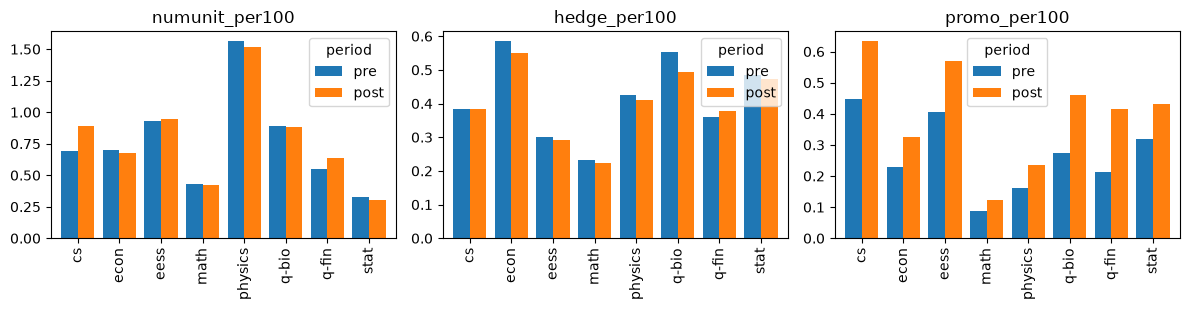

In [ ]:
# [For result] pre vs post means of the three main features
fig, axes = plt.subplots(1, 3, figsize=(12, 3.2))
for ax, c in zip(axes, MAIN):
    data.groupby(["field", "period"])[c].mean().unstack()[["pre", "post"]].plot.bar(ax=ax, color=["tab:blue", "tab:orange"], width=0.8)
    ax.set_title(c)
    ax.set_xlabel("")
plt.tight_layout()
plt.savefig("fig_features_by_field.png", dpi=200)